# CNN Development on a Custom Dataset — CIFAR-10

**Student ID:** Replace this with your ID  
**Course:** CVPR  
**Dataset:** CIFAR-10 (10 image classes)  
**Framework:** PyTorch

## Assignment objective
Build, train, validate, and evaluate a custom Convolutional Neural Network (CNN) for multi-class image classification. This notebook follows the workflow and training style used in the provided Cat-vs-Dog CNN example, and uses the save/load approach from the provided MNIST model example.

**Why CIFAR-10?** It is a publicly available, labelled, 10-class image dataset supported directly by `torchvision`. Each image is a 32×32 RGB image, which keeps the experiment manageable while providing a genuine multi-class classification task.

> Run the notebook from top to bottom. The first run downloads CIFAR-10, so an internet connection is required. Training time depends on your computer/GPU. Do not invent or manually type accuracy values; report the results produced by your run.

## 1. Import Libraries

We use PyTorch for the CNN and training loop, `torchvision` for CIFAR-10 and image transformations, Matplotlib for plots, and scikit-learn for the final classification metrics and confusion matrix.

In [1]:
# If any library is missing, uncomment and run:
# %pip install torch torchvision matplotlib numpy scikit-learn torchinfo

import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## 2. Load and Explore the Dataset

CIFAR-10 contains 60,000 colour images across 10 classes. The standard split contains 50,000 training images and 10,000 test images. We will take 10% of the original training set for validation, leaving 45,000 training images and 5,000 validation images.

The test set is kept separate and is used only for the final evaluation.

In [2]:
data_folder = "./data"
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

# Download the original training and test sets
train_raw = datasets.CIFAR10(root=data_folder, train=True, download=True)
test_raw = datasets.CIFAR10(root=data_folder, train=False, download=True)

print("Original training images:", len(train_raw))
print("Test images:", len(test_raw))
print("Classes:", train_raw.classes)
print("Class-to-index mapping:", train_raw.class_to_idx)

100%|██████████| 170M/170M [17:09<00:00, 166kB/s]


Original training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Class-to-index mapping: {'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}


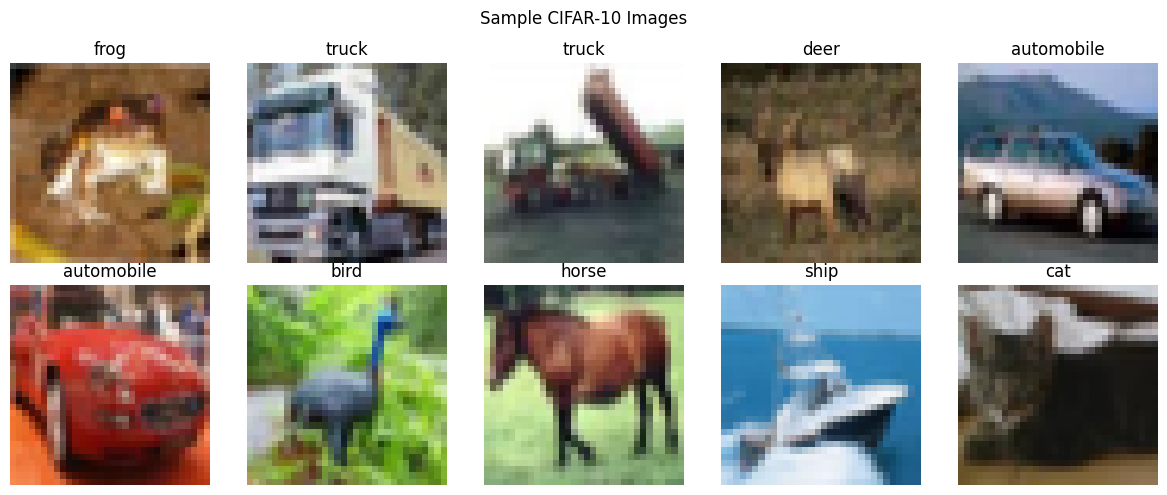

In [3]:
# Display a small sample of the dataset
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    image, label = train_raw[i]
    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis("off")
plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
plt.show()

## 3. Data Preprocessing and Augmentation

All CIFAR-10 images are already 32×32 RGB images. The training pipeline applies random horizontal flipping and random cropping as data augmentation. These transformations create slightly varied training examples and can help reduce overfitting.

We convert images to tensors and normalize each RGB channel using the standard CIFAR-10 channel means and standard deviations. Validation and test images use normalization only: random augmentation is not applied to evaluation data.

Separate dataset objects are used for the training and validation subsets so that validation images do not receive random training augmentation.

In [4]:
image_size = 32
batch_size = 64

cifar_mean = (0.4914, 0.4822, 0.4465)
cifar_std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(image_size, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std)
])

evaluation_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std)
])

# Two views of the same original training data: augmented and non-augmented
train_aug_dataset = datasets.CIFAR10(
    root=data_folder, train=True, download=False, transform=train_transform
)
train_eval_dataset = datasets.CIFAR10(
    root=data_folder, train=True, download=False, transform=evaluation_transform
)
test_dataset = datasets.CIFAR10(
    root=data_folder, train=False, download=False, transform=evaluation_transform
)

# Reproducible 90% / 10% split of the original training set
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_raw), generator=generator).tolist()
split_point = int(0.9 * len(indices))
train_indices = indices[:split_point]
val_indices = indices[split_point:]

train_data = Subset(train_aug_dataset, train_indices)
val_data = Subset(train_eval_dataset, val_indices)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Test samples:", len(test_dataset))

Training samples: 45000
Validation samples: 5000
Test samples: 10000


In [5]:
# DataLoaders create mini-batches for model training and evaluation.
# num_workers=0 is compatible with Windows and notebook environments.
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

# Check one batch shape
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)  # [batch, 3, 32, 32]
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])


## 4. Define a Custom CNN Architecture

The CNN has three feature-extraction blocks. Each block uses a convolution layer, ReLU activation, and max-pooling. The convolution layers learn visual patterns such as edges, textures, and object parts; max-pooling reduces the spatial dimensions.

The classifier converts the extracted features into 10 output scores (one for each CIFAR-10 class). The output layer does not include Softmax because `CrossEntropyLoss` expects raw logits.

**Architecture dimensions:** 32×32 → 16×16 → 8×8 → 4×4, with 128 feature channels before flattening.

In [6]:
def get_model():
    model = nn.Sequential(
        # Feature extraction block 1: 3 x 32 x 32 -> 32 x 16 x 16
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),

        # Feature extraction block 2: 32 x 16 x 16 -> 64 x 8 x 8
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),

        # Feature extraction block 3: 64 x 8 x 8 -> 128 x 4 x 4
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),

        # Classifier
        nn.Flatten(),
        nn.Linear(128 * 4 * 4, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 10)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer


# Hyperparameters
learning_rate = 1e-3
epoch_number = 15

model, loss_fn, optimizer = get_model()
print(model)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=2048, out_features=256, bias=True)
  (11): ReLU()
  (12): Dropout(p=0.3, inplace=False)
  (13): Linear(in_features=256, out_features=10, bias=True)
)


In [7]:
# Detailed layer-by-layer architecture summary
try:
    from torchinfo import summary
    summary(model, input_size=(1, 3, 32, 32), device=device)
except ImportError:
    print("Install torchinfo for a detailed summary: %pip install torchinfo")
    print("Total trainable parameters:",
          sum(p.numel() for p in model.parameters() if p.requires_grad))

Install torchinfo for a detailed summary: %pip install torchinfo
Total trainable parameters: 620362


## 5. Training and Validation Functions

For every training batch, the model predicts class logits, calculates cross-entropy loss, performs backpropagation, and updates weights using Adam. Accuracy is calculated by comparing the predicted class (`argmax`) with the true label.

During validation, `model.eval()` and `torch.no_grad()` disable training-specific behaviour and gradient calculation. Validation data is not used to update model weights.

In [8]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        batch_size_now = y.size(0)
        total_loss += batch_loss.item() * batch_size_now
        total_correct += (prediction.argmax(dim=1) == y).sum().item()
        total_samples += batch_size_now

    return total_loss / total_samples, total_correct / total_samples


@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)

        batch_size_now = y.size(0)
        total_loss += batch_loss.item() * batch_size_now
        total_correct += (prediction.argmax(dim=1) == y).sum().item()
        total_samples += batch_size_now

    return total_loss / total_samples, total_correct / total_samples

## 6. Train the CNN

The model is trained for 15 epochs. Training and validation loss/accuracy are recorded after each epoch. We also keep a copy of the weights with the best validation accuracy, so the final test evaluation uses the best validation checkpoint rather than automatically using the last epoch.

In [9]:
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(epoch_number):
    train_loss, train_accuracy = train_one_epoch(
        train_loader, model, loss_fn, optimizer
    )
    val_loss, val_accuracy = validation(
        val_loader, model, loss_fn
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_weights = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch + 1}/{epoch_number}] "
        f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy*100:.2f}% | "
        f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy*100:.2f}%"
    )

# Restore best validation model weights
model.load_state_dict(best_model_weights)
print(f"Best validation accuracy: {best_val_accuracy*100:.2f}%")

Epoch [1/15] Train Loss: 1.5925, Train Accuracy: 41.39% | Val Loss: 1.2720, Val Accuracy: 54.08%
Epoch [2/15] Train Loss: 1.2187, Train Accuracy: 56.47% | Val Loss: 1.0420, Val Accuracy: 62.20%
Epoch [3/15] Train Loss: 1.0533, Train Accuracy: 62.51% | Val Loss: 0.8979, Val Accuracy: 67.68%
Epoch [4/15] Train Loss: 0.9544, Train Accuracy: 66.26% | Val Loss: 0.8445, Val Accuracy: 69.82%
Epoch [5/15] Train Loss: 0.8894, Train Accuracy: 68.93% | Val Loss: 0.7738, Val Accuracy: 72.62%
Epoch [6/15] Train Loss: 0.8390, Train Accuracy: 70.46% | Val Loss: 0.7263, Val Accuracy: 74.78%
Epoch [7/15] Train Loss: 0.8025, Train Accuracy: 72.06% | Val Loss: 0.7268, Val Accuracy: 74.48%
Epoch [8/15] Train Loss: 0.7679, Train Accuracy: 73.41% | Val Loss: 0.6696, Val Accuracy: 75.80%
Epoch [9/15] Train Loss: 0.7429, Train Accuracy: 74.12% | Val Loss: 0.6439, Val Accuracy: 77.66%
Epoch [10/15] Train Loss: 0.7145, Train Accuracy: 75.22% | Val Loss: 0.6437, Val Accuracy: 76.90%
Epoch [11/15] Train Loss: 0.7

## 7. Visualize Training and Validation Curves

The loss curves show how prediction error changes over epochs. The accuracy curves show the proportion of correctly classified images. A large gap between training and validation performance can indicate overfitting; both curves should be considered when discussing model performance.

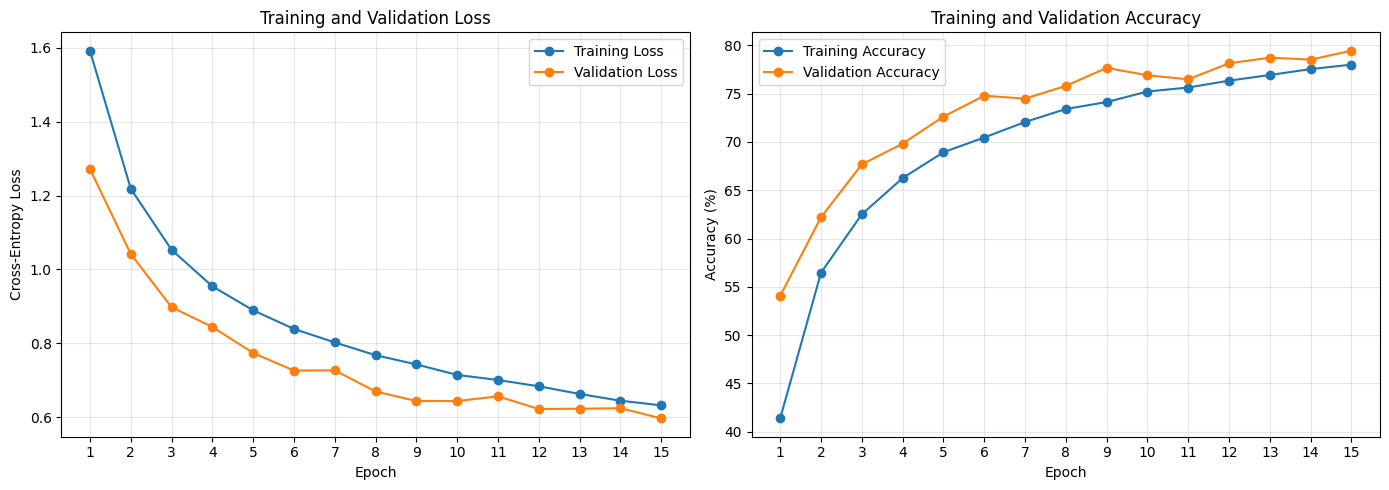

In [10]:
epochs = np.arange(1, epoch_number + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, np.array(train_accuracies) * 100, marker="o", label="Training Accuracy")
plt.plot(epochs, np.array(val_accuracies) * 100, marker="o", label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Evaluate the Model on the Test Set

The test set has not been used for training or model selection. We report test loss and accuracy, followed by precision, recall, and F1-score for each class. The confusion matrix helps identify which classes the model confuses with one another.

In [11]:
test_loss, test_accuracy = validation(test_loader, model, loss_fn)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

# Collect all predictions and true labels
all_predictions = []
all_labels = []

model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        logits = model(x)
        predictions = logits.argmax(dim=1).cpu().numpy()
        all_predictions.extend(predictions)
        all_labels.extend(y.numpy())

print("\nClassification Report:")
print(classification_report(
    all_labels, all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
))

Test Loss: 0.6240
Test Accuracy: 78.38%

Classification Report:
              precision    recall  f1-score   support

    airplane     0.7745    0.8310    0.8017      1000
  automobile     0.9115    0.8750    0.8929      1000
        bird     0.6285    0.7680    0.6913      1000
         cat     0.6776    0.5570    0.6114      1000
        deer     0.8301    0.6400    0.7228      1000
         dog     0.7130    0.7280    0.7204      1000
        frog     0.7841    0.8680    0.8239      1000
       horse     0.8060    0.8270    0.8164      1000
        ship     0.8846    0.8740    0.8793      1000
       truck     0.8614    0.8700    0.8657      1000

    accuracy                         0.7838     10000
   macro avg     0.7871    0.7838    0.7826     10000
weighted avg     0.7871    0.7838    0.7826     10000



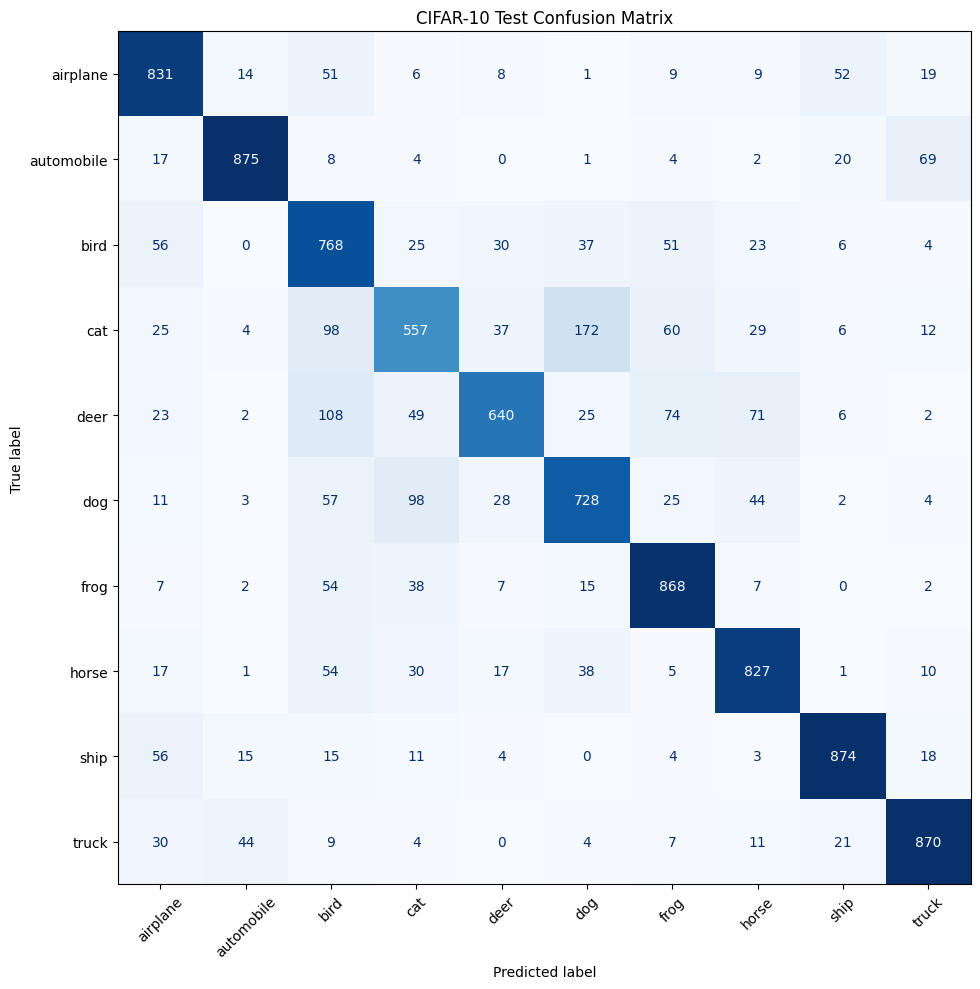

In [12]:
cm = confusion_matrix(all_labels, all_predictions)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(10, 10))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("CIFAR-10 Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Predict One Image

This cell selects one test image, predicts its class, and displays the confidence score. Softmax is used here only to convert the model's logits into class probabilities for display.

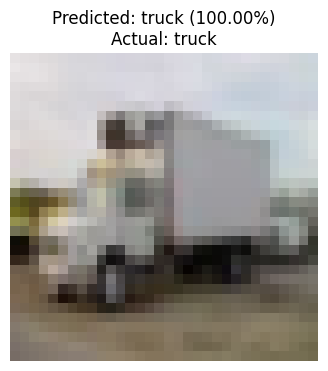

In [13]:
# CIFAR-10 normalization values, used to reverse normalization for display
mean_tensor = torch.tensor(cifar_mean).view(3, 1, 1)
std_tensor = torch.tensor(cifar_std).view(3, 1, 1)

random_index = random.randrange(len(test_dataset))
test_img, true_label = test_dataset[random_index]

model.eval()
with torch.no_grad():
    output = model(test_img.unsqueeze(0).to(device))
    probabilities = torch.softmax(output, dim=1)
    confidence, predicted_index = probabilities.max(dim=1)

# Undo normalization to display the original-looking image
display_img = (test_img * std_tensor + mean_tensor).clamp(0, 1)

plt.figure(figsize=(4, 4))
plt.imshow(display_img.permute(1, 2, 0))
plt.axis("off")
plt.title(
    f"Predicted: {class_names[predicted_index.item()]} "
    f"({confidence.item()*100:.2f}%)\n"
    f"Actual: {class_names[true_label]}"
)
plt.show()

## 10. Save the Trained Model Weights

As required by the assignment, we save the trained model weights in a `.pth` file. The checkpoint also stores the class names and key settings so that the model can be reconstructed correctly later.

The model file is intended for your GitHub submission if it is 20 MB or smaller. If it is larger than 20 MB, keep the file locally and follow the assignment instruction.

In [14]:
model_path = "cifar10_cnn_model.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "image_size": image_size,
    "learning_rate": learning_rate,
    "epoch_number": epoch_number
}, model_path)

print(f"Model saved to: {model_path}")
print(f"Model file size: {os.path.getsize(model_path) / (1024*1024):.2f} MB")

Model saved to: cifar10_cnn_model.pth
Model file size: 2.37 MB


## 11. Load the Saved Model

This section demonstrates model loading, following the state-dictionary workflow in the provided Model Save and Load example. We create a fresh model with the same architecture, load the saved weights, switch to evaluation mode, and check its test accuracy.

In [15]:
# Re-create the same architecture and load saved weights
loaded_model, _, _ = get_model()

checkpoint = torch.load(model_path, map_location=device)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

loaded_test_loss, loaded_test_accuracy = validation(
    test_loader, loaded_model, loss_fn
)
print(f"Loaded model test accuracy: {loaded_test_accuracy*100:.2f}%")

Loaded model test accuracy: 78.38%


## 12. Analysis and Discussion of Results

After running all cells, complete the points below using your actual output values.

1. **Dataset:** CIFAR-10 contains 10 classes of 32×32 RGB images. The experiment uses 45,000 training images, 5,000 validation images, and 10,000 test images.
2. **Preprocessing:** Training augmentation uses random cropping and horizontal flipping. All splits are converted to tensors and normalized.
3. **Architecture:** The custom CNN uses three convolution-ReLU-max-pooling blocks followed by fully connected layers. It outputs 10 logits for the 10 classes.
4. **Optimization:** Adam is used with learning rate 0.001, and CrossEntropyLoss is used for multi-class classification.
5. **Performance:** Record your actual best validation accuracy and test accuracy from the printed output.
6. **Learning curves:** Explain whether training and validation loss decrease, whether accuracy improves, and whether the gap suggests overfitting.
7. **Confusion matrix:** Mention the classes with the largest off-diagonal values (the most frequent confusions).

**Result values to fill after running:**
- Best validation accuracy: 79.44 %
- Test accuracy: 78.38 %
- Test loss: 0.6240

## 13. Conclusion and Future Work

This assignment implemented a complete multi-class image classification pipeline using a custom PyTorch CNN and the CIFAR-10 dataset. The notebook covers data loading, preprocessing, augmentation, data loaders, CNN architecture, model summary, training, validation, learning curves, test metrics, prediction, and saving/loading model weights.

**Future work:** Performance could be explored by training for more epochs, tuning the learning rate and batch size, adding batch normalization, using a learning-rate scheduler, or comparing the custom CNN with a deeper architecture. Any improvement should be verified using validation data and reported using the untouched test set.
